# 02 — Preprocessing dan Split

Notebook ini melakukan dua hal:

1. **Split per foto asli** (`origin_id`): 80% latih, 20% uji, stratified per kelas, `random_state=42`. Data uji hanya berisi foto asli; salinan augmentasi dari grup uji dibuang. Hasilnya disimpan di `results/split.csv` dan **data uji dikunci** sampai notebook 04.
2. **Preprocessing** yang sama untuk semua skenario: center-crop → resize 256×256 → grayscale → CLAHE. Di sini hanya divisualisasikan dengan data latih; ekstraksi fitur dilakukan di notebook 03 (latih) dan 04 (uji).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

from src.data import make_split
from src.preprocess import preprocess

FIG_DIR = config.FIGURES_DIR / "02_preprocessing"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Split per foto asli

Kenapa per `origin_id` dan bukan per file: satu foto asli punya 8 salinan augmentasi yang isinya kain yang sama. Kalau dibagi per file, salinan foto yang sama bisa masuk ke data latih dan data uji sekaligus, sehingga model cukup "mengingat kain" untuk menjawab benar. Dengan membagi tabel `origin_id` unik, setiap kain hanya ada di satu sisi.

Karena satu `origin_id` hanya punya satu kelas, stratifikasi cukup dilakukan pada tabel `origin_id` dengan `stratify=label`.

In [2]:
index = pd.read_csv(config.RESULTS_DIR / "dataset_index.csv")
split = make_split(index)
split.to_csv(config.RESULTS_DIR / "split.csv", index=False)
print(f"{len(split)} baris disimpan ke results/split.csv")
split.head()

4228 baris disimpan ke results/split.csv


,filename,label,origin_id,aug_type,split
0,Angguran/Angguran (1).jpg,Angguran,Angguran_1,original,train
1,Angguran/Angguran (1)_ChannelShuffle.jpg,Angguran,Angguran_1,ChannelShuffle,train
2,Angguran/Angguran (1)_ElasticTransform.jpg,Angguran,Angguran_1,ElasticTransform,train
3,Angguran/Angguran (1)_FDA.jpg,Angguran,Angguran_1,FDA,train
4,Angguran/Angguran (1)_Flip.jpg,Angguran,Angguran_1,Flip,train


In [3]:
train_ids = set(split.loc[split["split"] == "train", "origin_id"])
test_ids = set(split.loc[split["split"] == "test", "origin_id"])
assert train_ids.isdisjoint(test_ids), "ada origin_id di train dan test"
assert set(split.loc[split["split"] == "test", "aug_type"]) == {"original"}, "data uji berisi augmentasi"
dropped = len(index) - len(split)
print(f"origin_id latih: {len(train_ids)}, uji: {len(test_ids)}, tumpang tindih: 0")
print(f"Salinan augmentasi grup uji yang dibuang: {dropped} file")

origin_id latih: 457, uji: 115, tumpang tindih: 0
Salinan augmentasi grup uji yang dibuang: 920 file


In [4]:
table = pd.crosstab(
    split["label"],
    split["split"] + "_" + np.where(split["aug_type"] == "original", "asli", "augmentasi"),
)
table = table[["train_asli", "train_augmentasi", "test_asli"]]
table.loc["TOTAL"] = table.sum()
table

split,train_asli,train_augmentasi,test_asli
label,,,
Angguran,42,336,10
Ayam Puger,42,336,10
Jahe Lumbon,42,336,10
Jahe Puger,41,328,11
Jahe Srimpang,41,328,11
Lumbon,42,336,10
Madu Bronto,41,328,11
Pring Sedapur,41,328,11
Puger Galar,41,328,11


Eksperimen utama (Opsi A) hanya memakai kolom `train_asli` untuk latih. Kolom `train_augmentasi` baru dipakai di ablasi Opsi B (notebook 05).

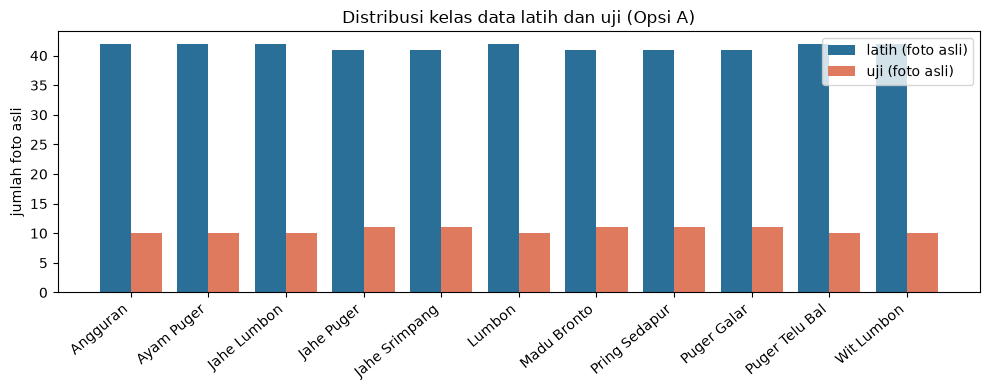

In [5]:
plot_t = table.drop(index="TOTAL")
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(plot_t))
ax.bar(x - 0.2, plot_t["train_asli"], width=0.4, label="latih (foto asli)", color="#2a6f97")
ax.bar(x + 0.2, plot_t["test_asli"], width=0.4, label="uji (foto asli)", color="#e07a5f")
ax.set_xticks(x, plot_t.index, rotation=40, ha="right")
ax.set_ylabel("jumlah foto asli")
ax.set_title("Distribusi kelas data latih dan uji (Opsi A)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "distribusi_train_test.png", dpi=150)
plt.show()

## 2. Preprocessing

Urutan dan alasannya:

| Langkah | Alasan |
|---|---|
| Center-crop ke persegi | Semua citra sudah 512×512, jadi langkah ini tidak mengubah apa pun; tetap dipasang supaya pipeline aman untuk citra lain. |
| Resize ke 256×256 (`anti_aliasing=True`) | Downscale 2×, tanpa interpolasi naik. Anti-aliasing meredam noise halus sebelum LBP. Alasan lengkap di `note.md`. |
| Grayscale 0,299R + 0,587G + 0,114B | GLCM dan LBP bekerja pada intensitas. Bobot sama dengan `rgb2gray` MATLAB dan persamaan (1) Fatimah. |
| CLAHE, `clip_limit=0.01` | Meratakan kontras lokal, sehingga perbedaan pencahayaan antar-foto (bayangan, lantai) tidak terbaca sebagai tekstur. *Clip limit* membatasi penguatan supaya noise di area rata tidak ikut diperkuat. Setara default `adapthisteq` MATLAB. |
| Tanpa sharpening | Sharpening memperkuat noise frekuensi tinggi, dan LBP R=1 langsung terpengaruh. |

Semua langkah dihitung per citra dari pikselnya sendiri, jadi tidak ada informasi yang bocor antar-citra (tidak ada statistik yang di-*fit* pada seluruh dataset).

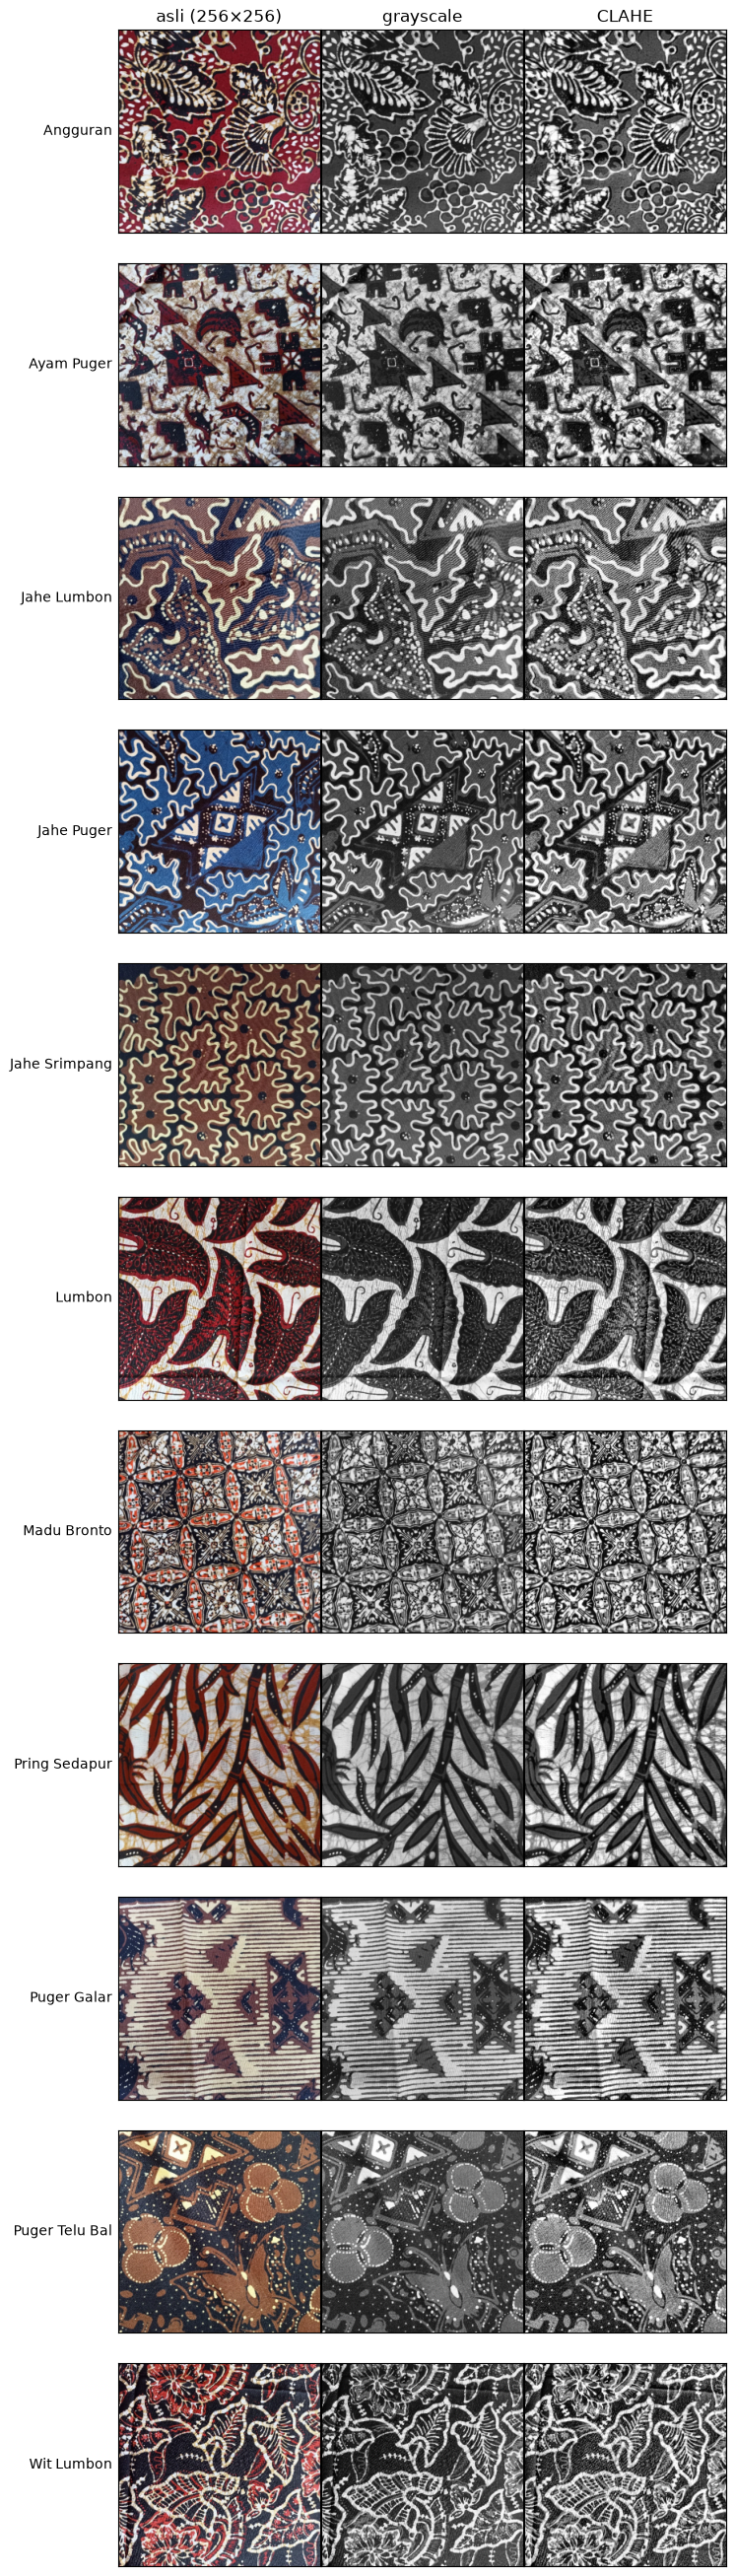

In [6]:
train_orig = split[(split["split"] == "train") & (split["aug_type"] == "original")].reset_index(drop=True)
examples = train_orig.groupby("label").first().loc[config.CLASSES, "filename"]

fig, axes = plt.subplots(len(config.CLASSES), 3, figsize=(7.5, 2.4 * len(config.CLASSES)))
for i, (cls, fn) in enumerate(examples.items()):
    steps = preprocess(config.RAW_DIR / fn, return_steps=True)
    for j, (key, title) in enumerate([("rgb", "asli (256×256)"), ("gray", "grayscale"), ("clahe", "CLAHE")]):
        ax = axes[i, j]
        ax.imshow(steps[key], cmap=None if key == "rgb" else "gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(title)
        if j == 0:
            ax.set_ylabel(cls, rotation=0, ha="right", va="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "tahap_preprocessing_per_kelas.png", dpi=80)
plt.show()

## 3. Karakteristik data akhir: histogram intensitas

Histogram rata-rata dihitung dari seluruh foto asli data latih, sebelum dan sesudah CLAHE. CLAHE seharusnya membuat sebaran intensitas lebih lebar dan merata, sehingga perbedaan kecerahan antar-foto berkurang.

In [7]:
from joblib import Parallel, delayed


def hist_pair(fn):
    s = preprocess(config.RAW_DIR / fn, return_steps=True)
    return (np.bincount(s["gray"].ravel(), minlength=256), np.bincount(s["clahe"].ravel(), minlength=256),
            s["gray"].std(), s["clahe"].std())


res = Parallel(n_jobs=-1)(delayed(hist_pair)(fn) for fn in train_orig["filename"])
h_gray = np.mean([r[0] for r in res], axis=0) / (config.IMG_SIZE ** 2)
h_clahe = np.mean([r[1] for r in res], axis=0) / (config.IMG_SIZE ** 2)
std_gray = np.array([r[2] for r in res]); std_clahe = np.array([r[3] for r in res])
print(f"{len(res)} foto asli latih")
print(f"Simpangan baku intensitas per citra (median): grayscale {np.median(std_gray):.1f}, CLAHE {np.median(std_clahe):.1f}")

457 foto asli latih
Simpangan baku intensitas per citra (median): grayscale 63.5, CLAHE 73.7


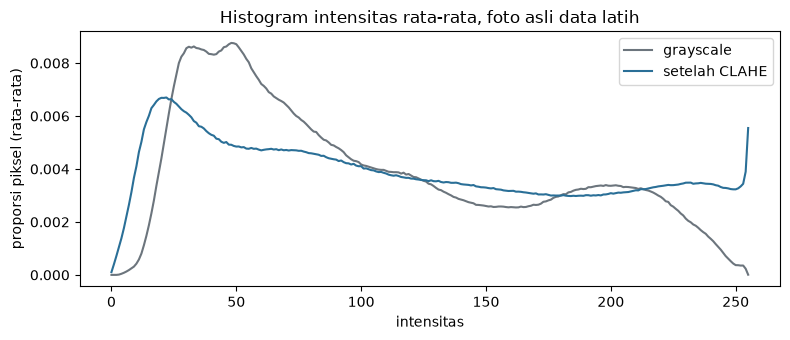

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(h_gray, label="grayscale", color="#6c757d")
ax.plot(h_clahe, label="setelah CLAHE", color="#2a6f97")
ax.set_xlabel("intensitas"); ax.set_ylabel("proporsi piksel (rata-rata)")
ax.set_title("Histogram intensitas rata-rata, foto asli data latih")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "histogram_intensitas.png", dpi=150)
plt.show()

## Ringkasan

- `results/split.csv` berisi pembagian final. Notebook 03 hanya memakai baris `split == "train"`; baris `test` baru dibaca di notebook 04.
- Preprocessing diterapkan saat ekstraksi fitur (`src/preprocess.py`), jadi tidak ada citra hasil preprocessing yang disimpan ke disk.

In [9]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 8 detik
